# Using Cross Validation to to measure performance
---

## Preliminary Steps
---

In [2]:
from pprint import pprint

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Read the data
train_data = pd.read_csv('../input/home-data-for-ml-course_competition/train.csv', index_col='Id')
test_data = pd.read_csv('../input/home-data-for-ml-course_competition/test.csv', index_col='Id')

# Remove rows with missing target, separate target from predictors
train_data.dropna(axis=0, subset=['SalePrice'], inplace=True)
y = train_data.SalePrice              
train_data.drop(['SalePrice'], axis=1, inplace=True)

# Select numeric columns only
numeric_cols = [cname for cname in train_data.columns if train_data[cname].dtype in ['int64', 'float64']]
X = train_data[numeric_cols].copy()
X_test = test_data[numeric_cols].copy()

In [4]:
X.head()

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold
Id,,,,,,,,,,,,,,,,,,,,,
1,60,65.0,8450,7,5,2003,2003,196.0,706,0,...,548,0,61,0,0,0,0,0,2,2008
2,20,80.0,9600,6,8,1976,1976,0.0,978,0,...,460,298,0,0,0,0,0,0,5,2007
3,60,68.0,11250,7,5,2001,2002,162.0,486,0,...,608,0,42,0,0,0,0,0,9,2008
4,70,60.0,9550,7,5,1915,1970,0.0,216,0,...,642,0,35,272,0,0,0,0,2,2006
5,60,84.0,14260,8,5,2000,2000,350.0,655,0,...,836,192,84,0,0,0,0,0,12,2008


## First Steps
---

So far, you've learned how to build pipelines with scikit-learn. For instance, the pipeline below will use `SimpleImputer()` to replace missing values in the data, before using `RandomForestRegressor()` to train a random forest model to make predictions. We set the number of trees in the random forest model with the `n_estimators` parameter, and setting `random_state` ensures reproducibility.

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

my_pipeline = Pipeline(steps=[
    ('preprocessor', SimpleImputer()),
    ('model', RandomForestRegressor(n_estimators=50, random_state=0))
])

You have also learned how to use pipelines in cross-validation. The code below uses the `cross_val_score()` function to obtain **the mean absolute error (MAE)**, averaged across five different folds.

In [6]:
from sklearn.model_selection import cross_val_score

# Multiply by -1 since sklearn calculates *negative* MAE
scores = -1 * cross_val_score(my_pipeline, X, y,
                              cv=5,
                              scoring='neg_mean_absolute_error')

print("MAE scores:\n", scores)
print("\nAverage MAE score:", scores.mean())

MAE scores:
 [18549.88568493 17896.67034247 18462.68472603 16587.02472603
 19885.78630137]

Average MAE score: 18276.410356164386


## Step 1: Write a useful function
---

In this exercise, you'll use cross-validation to select parameters for a machine learning model.

Begin by writing a function `get_score()` that reports the average (over three cross-validation folds) MAE of a machine learning pipeline that uses:

- the data in `X` and `y` to create folds,
- `SimpleImputer()` (with all parameters left as default) to replace missing values, and
- `RandomForestRegressor()` (with `random_state=0`) to fit a random forest model.

The `n_estimators` parameter supplied to `get_score()` is used when setting the number of trees in the random forest model.

In [7]:
def get_score(n_estimators):
    """Return the average MAE over 3 CV folds of random forest model.
    
    Keyword argument:
    n_estimators -- the number of trees in the forest
    """
    my_pipeline = Pipeline(steps=[
        ('preprocessor', SimpleImputer()),
        ('model', RandomForestRegressor(n_estimators=n_estimators, random_state=0))
    ])

    scores = -1 * cross_val_score(my_pipeline, X, y,
                              cv=3,
                              scoring='neg_mean_absolute_error')

    average_MAE = scores.mean()
    
    return average_MAE

## Step 2: Test different parameter values
---

Now, you will use the function that you defined in Step 1 to evaluate the model performance corresponding to eight different values for the number of trees in the random forest: 50, 100, 150, ..., 300, 350, 400.

Store your results in a Python dictionary `results`, where `results[i]` is the average MAE returned by `get_score(i)`.

In [8]:
results = dict()
for n_leaf in range(50, 400+1, 50):
    results[n_leaf] = get_score(n_leaf)

pprint(results)

{50: np.float64(18353.8393511688),
 100: np.float64(18395.2151680032),
 150: np.float64(18288.730020956387),
 200: np.float64(18248.345889801505),
 250: np.float64(18255.26922247291),
 300: np.float64(18275.241922621914),
 350: np.float64(18270.29183308043),
 400: np.float64(18270.197974402367)}


Use the next cell to visualize your results from Step 2. Run the code without changes.

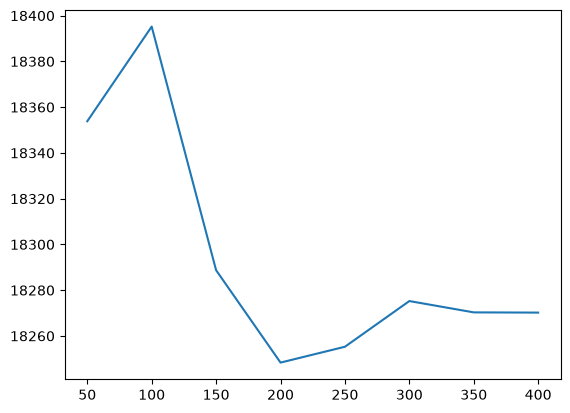

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.plot(list(results.keys()), list(results.values()))
plt.show()

**Notes about** `%matplotlib inline`**:**  Esa línea que comienza con un símbolo de porcentaje es un comando mágico de IPython (una característica exclusiva de entornos interactivos como Jupyter Notebook o JupyterLab).

Su función: Le indica a Jupyter que pinte los gráficos de Matplotlib directamente dentro del documento (en línea, justo debajo de la celda de código) en lugar de intentar abrirlos en una ventana flotante separada.

## Step 3: Find the best parameter value
---

Given the results, which value for n_estimators seems best for the random forest model? Use your answer to set the value of `n_estimators_best`.

In [9]:
n_estimators_best = 200

## Conclusion
---

This exercise provided one method for choosing appropriate parameters in a machine learning model.

If you'd like to learn more about [hyperparameter optimization](https://en.wikipedia.org/wiki/Hyperparameter_optimization), you're encouraged to start with **grid search**, which is a straightforward method for determining the best _combination_ of parameters for a machine learning model.  Thankfully, scikit-learn also contains a built-in function [`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) that can make your grid search code very efficient!